<a href="https://colab.research.google.com/github/Maxime-frs/Capital-preservation-Portfolio-optimization/blob/main/Pick_20_Capital_Preservation_10y.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capital Preservation: pick 20 stocks out of 1,000 and weight them (10-year history)

**Profile:** capital preservation. **Constraints:** stable revenue · portfolio max drawdown ≤ 10 % · beta of every stock ≤ 1.2

**Funnel**
1. **Data quality & liquidity**: full price history, no bad price spikes, not stale, ≥ $1M traded per day, no investment funds/trusts
2. **Beta ≤ 1.2**: three betas checked, each ≤ 1.2: vs the stock's **local index**, vs the **MSCI ACWI** world index (in USD), and Yahoo's own figure
3. **History**: at least 10 years of prices (`LOOKBACK_YEARS`), so the 2018 sell-off, the COVID crash, 2022 and 2025 are all included
4. **Risk pre-screen**: the 150 lowest-risk survivors (volatility, max drawdown, tail loss)
5. **Stable revenue**: at least 3 years of revenue, no year down more than 5 %, growth volatility ≤ 10 pts
6. **Ranking & picking**: composite score, one listing per company, ≤ 4 per sector, ≤ 6 per country → **20 stocks**
7. **Weighting**: max Sharpe s.t. **max drawdown ≤ 8 %** in-sample (2 pt buffer), 2 %–10 % per stock, sector ≤ 25 %
8. **Validation**: the whole pipeline is re-run as of 1 year ago and tested on the following 12 months it never saw
9. **Independent verification**: every constraint recomputed a second way

All returns are in **USD** (change `BASE_CCY` for EUR).

In [ ]:
!pip install -q yfinance scipy
import warnings, time, io, re
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, yfinance as yf
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from concurrent.futures import ThreadPoolExecutor
import logging; logging.getLogger("yfinance").setLevel(logging.CRITICAL)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
np.random.seed(42)

## 1. Parameters

In [ ]:
# --- hackathon constraints ---
MAX_DRAWDOWN   = 0.10
DD_TARGET      = 0.08     # optimizer target (safety buffer)
MAX_STOCK_BETA = 1.20
# --- revenue stability ---
MIN_REV_GROWTH, MAX_REV_GROWTH_STD, MIN_REV_YEARS = -0.05, 0.10, 3
# --- data quality / liquidity ---
MIN_COVERAGE, MAX_DAILY_MOVE, MAX_STALE_FRAC, MIN_ADV_USD = 0.95, 0.35, 0.20, 1e6
# --- portfolio ---
N_STOCKS, PRESCREEN_N = 20, 150
MAX_PER_SECTOR_N, MAX_PER_COUNTRY_N = 4, 6
W_MIN, W_MAX, SECTOR_CAP, MAX_PORT_BETA = 0.02, 0.10, 0.25, 0.80
SHRINK_MU = 0.5
BASE_CCY  = "USD"
LOOKBACK_YEARS = 10       # history used for beta, risk, drawdown & optimization
TODAY      = pd.Timestamp.today().normalize()
TEST_START = TODAY - pd.DateOffset(years=1)
DATA_START = TODAY - pd.DateOffset(years=LOOKBACK_YEARS + 1, weeks=3)
print("Data from", DATA_START.date(), "| validation split", TEST_START.date())

Data from 2015-10-21 | validation split 2025-11-11


## 2. Universe (the 1,000 tickers provided)

In [ ]:
UNIVERSE_CSV = """name,ticker
Newmont Corporation,NEM.AX
Newmont Corporation,NEM
Freeport-McMoRan Inc.,FCX
Franco-Nevada Corporation,FNV.TO
"PPG Industries, Inc.",PPG
Dow Inc.,DOW
"CF Industries Holdings, Inc.",CF
"Solstice Advanced Materials, Inc.",SOLS
Axalta Coating Systems Ltd.,AXTA
Cleveland-Cliffs Inc.,CLF
The Mosaic Company,MOS
MP Materials Corp.,MP
Capstone Copper Corp.,CSC.AX
Celanese Corporation,CE
"Warrior Met Coal, Inc.",HCC
"United States Lime & Minerals, Inc.",USLM
Knife River Corporation,KNF
"Hawkins, Inc.",HWKN
WD-40 Company,WDFC
Innospec Inc.,IOSP
Kaiser Aluminum Corporation,KALU
FMC Corporation,FMC
Amaroq Ltd.,AMRQ.L
Alphabet Inc.,GOOGL
Alphabet Inc.,GOOG
"Netflix, Inc.",NFLX
The Walt Disney Company,DIS
Verizon Communications Inc.,VZ
AT&T Inc.,T
AppLovin Corporation,APP
Fox Corporation,FOXA
News Corporation,NWS.AX
News Corporation,NWSA
"Match Group, Inc.",MTCH
Iridium Communications Inc.,IRDM
"Lumen Technologies, Inc.",LUMN
"Versant Media Group, Inc.",VSNT
"Cinemark Holdings, Inc.",CNK
"DoubleVerify Holdings, Inc.",DV
Yelp Inc.,YELP
"QuinStreet, Inc.",QNST
Scholastic Corporation,SCHL
Shenandoah Telecommunications Company,SHEN
"Cogent Communications Holdings, Inc.",CCOI
"Cable One, Inc.",CABO
"Amazon.com, Inc.",AMZN
"The Home Depot, Inc.",HD
"Airbnb, Inc.",ABNB
"O'Reilly Automotive, Inc.",ORLY
Ford Motor Company,F
Carnival Corporation Ltd.,CCL
"Williams-Sonoma, Inc.",WSM
"PulteGroup, Inc.",PHM
International Paper Company,IP
Hyatt Hotels Corporation,H
Genuine Parts Company,GPC
"Five Below, Inc.",FIVE
lululemon athletica inc.,LULU
"Life Time Group Holdings, Inc.",LTH
"Allison Transmission Holdings, Inc.",ALSN
BorgWarner Inc.,BWA
Murphy USA Inc.,MUSA
"Chewy, Inc.",CHWY
Norwegian Cruise Line Holdings Ltd.,NCLH
MGM Resorts International,MGM
"CAVA Group, Inc.",CAVA
Abercrombie & Fitch Co.,ANF
"Light & Wonder, Inc.",LNW.AX
Dutch Bros Inc.,BROS
Atmus Filtration Technologies Inc.,ATMU
"Bath & Body Works, Inc.",BBWI
"Boot Barn Holdings, Inc.",BOOT
Marriott Vacations Worldwide Corporation,VAC
Kohl's Corporation,KSS
Dana Incorporated,DAN
LCI Industries,LCII
"The Buckle, Inc.",BKE
"Under Armour, Inc.",UA
Whirlpool Corporation,WHR
Albany International Corp.,AIN
United Parks & Resorts Inc.,PRKS
"Pursuit Attractions and Hospitality, Inc.",PRSU
"MillerKnoll, Inc.",MLKN
"Liquidity Services, Inc.",LQDT
"G-III Apparel Group, Ltd.",GIII
"MasterBrand, Inc.",MBC
"Carter's, Inc.",CRI
Winmark Corporation,WINA
"Tripadvisor, Inc.",TRIP
The Coca-Cola Company,KO
The Procter & Gamble Company,PG
"PepsiCo, Inc.",PEP
"Altria Group, Inc.",MO
"Mondelez International, Inc.",MDLZ
Target Corporation,TGT
The Estée Lauder Companies Inc.,EL
The Kroger Co.,KR
The Kraft Heinz Company,KHC
"General Mills, Inc.",GIS
"Lamb Weston Holdings, Inc.",LW
The Campbell's Company,CPB
Pilgrim's Pride Corporation,PPC
"PriceSmart, Inc.",PSMT
"Laureate Education, Inc.",LAUR
"Sprouts Farmers Market, Inc.",SFM
"Interparfums, Inc.",IPAR
Coty Inc.,COTY
"The Vita Coco Company, Inc.",COCO
"Post Holdings, Inc.",POST
"Cal-Maine Foods, Inc.",CALM
"Freshpet, Inc.",FRPT
"Grand Canyon Education, Inc.",LOPE
Newell Brands Inc.,NWL
"The Andersons, Inc.",ANDE
Perdoceo Education Corporation,PRDO
J&J Snack Foods Corp.,JJSF
"Flowers Foods, Inc.",FLO
"Strategic Education, Inc.",STRA
The Simply Good Foods Company,SMPL
"The Hain Celestial Group, Inc.",HAIN
Chevron Corporation,CVX
Enbridge Inc.,ENB.TO
"Kinder Morgan, Inc.",KMI
TC Energy Corporation,TRP.TO
Devon Energy Corporation,DVN
EQT Corporation,EQT
Pembina Pipeline Corporation,PPL.TO
Expand Energy Corporation,EXE
Texas Pacific Land Corporation,TPL
"DT Midstream, Inc.",DTM
Antero Midstream Corporation,AM
Kinetik Holdings Inc.,KNTK
Matador Resources Company,MTDR
NexGen Energy Ltd.,NXG.AX
CNX Resources Corporation,CNX
"Archrock, Inc.",AROC
"Kodiak Gas Services, Inc.",KGS
"Comstock Resources, Inc.",CRK
California Resources Corporation,CRC
"Core Natural Resources, Inc.",CNR
"Patterson-UTI Energy, Inc.",PTEN
Tidewater Inc.,TDW
Talos Energy Inc.,TALO
Liberty Energy Inc.,LBRT
Peabody Energy Corporation,BTU
"Innovex International, Inc.",INVX
Core Laboratories Inc.,CLB
Berkshire Hathaway Inc.,BRK-B
Mastercard Incorporated,MA
Bank of America Corporation,BAC
Royal Bank of Canada,RY.TO
"The Goldman Sachs Group, Inc.",GS
Wells Fargo & Company,WFC
American Express Company,AXP
"BlackRock, Inc.",BLK
Blackstone Inc.,BX
S&P Global Inc.,SPGI
Brookfield Asset Management Ltd.,BAM.TO
"Robinhood Markets, Inc.",HOOD
"The Hartford Insurance Group, Inc.",HIG
Intact Financial Corporation,IFC.TO
Huntington Bancshares Incorporated,HBAN
"Brown & Brown, Inc.",BRO
"T. Rowe Price Group, Inc.",TROW
The Carlyle Group Inc.,CG
Invesco Ltd.,IVZ
FactSet Research Systems Inc.,FDS
Ally Financial Inc.,ALLY
Evercore Inc.,EVR
"Houlihan Lokey, Inc.",HLI
"Voya Financial, Inc.",VOYA
"Primerica, Inc.",PRI
"Pershing Square Holdings, Ltd.",PSH.L
"Columbia Banking System, Inc.",COLB
RLI Corp.,RLI
"Lazard, Inc.",LAZ
"Palomar Holdings, Inc.",PLMR
First BanCorp.,FBP
"Bread Financial Holdings, Inc.",BFH
Assured Guaranty Ltd.,AGO
"Banc of California, Inc.",BANC
"MARA Holdings, Inc.",MARA
First Bancorp,FBNC
"Brighthouse Financial, Inc.",BHF
"HCI Group, Inc.",HCI
"Northwest Bancshares, Inc.",NWBI
City Holding Company,CHCO
"EZCORP, Inc.",EZPW
"Hope Bancorp, Inc.",HOPE
"CleanSpark, Inc.",CLSK
"Goosehead Insurance, Inc.",GSHD
GQG Partners Inc.,GQG.AX
"Safety Insurance Group, Inc.",SAFT
"Trupanion, Inc.",TRUP
Tompkins Financial Corporation,TMP
RTW Biotech Opportunities Ltd,RTW.L
Neuberger Private Equity Partners Limited,NBPE.L
Green Dot Corporation,GDOT
Johnson & Johnson,JNJ
AbbVie Inc.,ABBV
"Merck & Co., Inc.",MRK
"Gilead Sciences, Inc.",GILD
Pfizer Inc.,PFE
McKesson Corporation,MCK
"Cencora, Inc.",COR
"IDEXX Laboratories, Inc.",IDXX
Veeva Systems Inc.,VEEV
ResMed Inc.,RMD.AX
"Illumina, Inc.",ILMN
Tenet Healthcare Corporation,THC
"Neurocrine Biosciences, Inc.",NBIX
Glaukos Corporation,GKOS
Elanco Animal Health Incorporated,ELAN
"Penumbra, Inc.",PEN
"The Ensign Group, Inc.",ENSG
"Molina Healthcare, Inc.",MOH
"Avantor, Inc.",AVTR
"Bio-Rad Laboratories, Inc.",BIO
Bruker Corporation,BRKR
"Protagonist Therapeutics, Inc.",PTGX
Chemed Corporation,CHE
"Arrowhead Pharmaceuticals, Inc.",ARWR
"Doximity, Inc.",DOCS
"Option Care Health, Inc.",OPCH
Warby Parker Inc.,WRBY
National HealthCare Corporation,NHC
"ADMA Biologics, Inc.",ADMA
Addus HomeCare Corporation,ADUS
"Vir Biotechnology, Inc.",VIR
Prestige Consumer Healthcare Inc.,PBH
"Harmony Biosciences Holdings, Inc.",HRMY
"Veracyte, Inc.",VCYT
BioLife Solutions Inc,BLFS
"Certara, Inc.",CERT
"LeMaitre Vascular, Inc.",LMAT
"Healthcare Services Group, Inc.",HCSG
Enovis Corporation,ENOV
"Alignment Healthcare, Inc.",ALHC
CONMED Corporation,CNMD
"Amphastar Pharmaceuticals, Inc.",AMPH
"HealthStream, Inc.",HSTM
"Collegium Pharmaceutical, Inc.",COLL
GE Aerospace,GE
Caterpillar Inc.,CAT
"Quanta Services, Inc.",PWR
Northrop Grumman Corporation,NOC
"L3Harris Technologies, Inc.",LHX
"Old Dominion Freight Line, Inc.",ODFL
Global Payments Inc.,GPN
Xylem Inc.,XYL
"XPO, Inc.",XPO
IDEX Corporation,IEX
Masco Corporation,MAS
"Huntington Ingalls Industries, Inc.",HII
"Mueller Industries, Inc.",MLI
"Advanced Drainage Systems, Inc.",WMS
ADT Inc.,ADT
"Matson, Inc.",MATX
"Amentum Holdings, Inc.",AMTM
Granite Construction Incorporated,GVA
"FTI Consulting, Inc.",FCN
"Mercury Systems, Inc.",MRCY
"CSW Industrials, Inc.",CSW
"Avis Budget Group, Inc.",CAR
Korn Ferry,KFY
"Mueller Water Products, Inc.",MWA
First Advantage Corporation,FA
WillScot Holdings Corporation,WSC
"Worthington Enterprises, Inc.",WOR
"Trinity Industries, Inc.",TRN
JetBlue Airways Corporation,JBLU
"Arlo Technologies, Inc.",ARLO
"Apogee Enterprises, Inc.",APOG
Quanex Building Products Corporation,NX
"Astec Industries, Inc.",ASTE
"Heartland Express, Inc.",HTLD
"LegalZoom.com, Inc.",LZ
"Prologis, Inc.",PLD
"Digital Realty Trust, Inc.",DLR
Extra Space Storage Inc.,EXR
VICI Properties Inc.,VICI
Kimco Realty Corporation,KIM
"EastGroup Properties, Inc.",EGP
"Alexandria Real Estate Equities, Inc.",ARE
Terreno Realty Corporation,TRNO
Healthcare Realty Trust Incorporated,HR
"Phillips Edison & Company, Inc.",PECO
"Millrose Properties, Inc.",MRP
Curbline Properties Corp.,CURB
"National Health Investors, Inc.",NHI
DiamondRock Hospitality Company,DRH
InvenTrust Properties Corp.,IVT
Pebblebrook Hotel Trust,PEB
"Douglas Emmett, Inc.",DEI
Getty Realty Corp.,GTY
Safehold Inc.,SAFE
"Adamas Trust, Inc.",ADAM
"Hudson Pacific Properties, Inc.",HPP
"AGNT, Inc",AGNT
Microsoft Corporation,MSFT
Intel Corporation,INTC
"Arista Networks, Inc.",ANET
"CrowdStrike Holdings, Inc.",CRWD
International Business Machines Corporation,IBM
Shopify Inc.,SHOP.TO
QUALCOMM Incorporated,QCOM
Lumentum Holdings Inc.,LITE
"Okta, Inc.",OKTA
Teledyne Technologies Incorporated,TDY
Cognizant Technology Solutions Corporation,CTSH
"VeriSign, Inc.",VRSN
Fortive Corporation,FTV
"First Solar, Inc.",FSLR
"Skyworks Solutions, Inc.",SWKS
"F5, Inc.",FFIV
"Leidos Holdings, Inc.",LDOS
CACI International Inc,CACI
"Jack Henry & Associates, Inc.",JKHY
"SailPoint, Inc.",SAIL
Semtech Corporation,SMTC
"Qorvo, Inc.",QRVO
"DigitalOcean Holdings, Inc.",DOCN
"Amkor Technology, Inc.",AMKR
Ralliant Corporation,RAL
"Duolingo, Inc.",DUOL
"UiPath, Inc.",PATH
Science Applications International Corporation,SAIC
ESCO Technologies Inc.,ESE
"Qualys, Inc.",QLYS
Open Text Corporation,OTEX.TO
"Box, Inc.",BOX
Parsons Corporation,PSN
"Impinj, Inc.",PI
"MaxLinear, Inc.",MXL
"Enphase Energy, Inc.",ENPH
"Life360, Inc.",360.AX
"Extreme Networks, Inc.",EXTR
Teradata Corporation,TDC
"Sonos, Inc.",SONO
"Calix, Inc.",CALX
"EVERTEC, Inc.",EVTC
Concentrix Corporation,CNXC
"Donnelley Financial Solutions, Inc.",DFIN
"Upbound Group, Inc.",UPBD
NCR Voyix Corporation,VYX
"Corsair Gaming, Inc.",CRSR
"Ichor Holdings, Ltd.",ICHR
Cerence Inc.,CRNC
3D Systems Corporation,DDD
SunPower Inc.,SPWR
"Dominion Energy, Inc.",D
Xcel Energy Inc.,XEL
Exelon Corporation,EXC
Brookfield Infrastructure Partners L.P.,BIP-UN.TO
Edison International,EIX
NiSource Inc.,NI
"Evergy, Inc.",EVRG
"NRG Energy, Inc.",NRG
Emera Incorporated,EMA.TO
"Clearway Energy, Inc.",CWEN
American States Water Company,AWR
Northwest Natural Holding Company,NWN
Middlesex Water Company,MSEX
BHP Group Limited,BHP.AX
Fortescue Ltd,FMG.AX
Northern Star Resources Limited,NST.AX
Nippon Steel Corporation,5401.T
South32 Limited,S32.AX
Sandfire Resources Limited,SFR.AX
Xinyi Glass Holdings Limited,0868.HK
Dyno Nobel Limited,DNL.AX
Regis Resources Limited,RRL.AX
PDI Gold Limited,PDI.AX
IGO Limited,IGO.AX
Fletcher Building Limited,FBU.AX
Nickel Industries Limited,NIC.AX
Bellevue Gold Limited,BGL.AX
Deterra Royalties Limited,DRR.AX
Perenti Limited,PRN.AX
Redox Limited,RDX.AX
Catalyst Metals Limited,CYL.AX
China Mobile Limited,0941.HK
"Recruit Holdings Co., Ltd.",6098.T
SoftBank Group Corp.,9984.T
"NTT, Inc.",9432.T
KDDI Corporation,9433.T
"Nintendo Co., Ltd.",7974.T
Telstra Group Limited,TLS.AX
REA Group Limited,REA.AX
CAR Group Limited,CAR.AX
TPG Telecom Limited,TPG.AX
SEEK Limited,SEK.AX
Spark New Zealand Limited,SPK.AX
Chorus Limited,CNU.AX
EVT Limited,EVT.AX
Tuas Limited,TUA.AX
Toyota Motor Corporation,7203.T
"Fast Retailing Co., Ltd.",9983.T
Wesfarmers Limited,WES.AX
"Honda Motor Co., Ltd.",7267.T
"Oriental Land Co., Ltd.",4661.T
DENSO Corporation,6902.T
Trip.com Group Limited,9961.HK
Aristocrat Leisure Limited,ALL.AX
Galaxy Entertainment Group Limited,0027.HK
The Lottery Corporation Limited,TLC.AX
Shenzhou International Group Holdings Limited,2313.HK
Breville Group Limited,BRG.AX
Lovisa Holdings Limited,LOV.AX
Super Retail Group Limited,SUL.AX
Premier Investments Limited,PMV.AX
Tabcorp Holdings Limited,TAH.AX
Orora Limited,ORA.AX
ARB Corporation Limited,ARB.AX
Corporate Travel Management Limited,CTD.AX
Japan Tobacco Inc.,2914.T
"Ajinomoto Co., Inc.",2802.T
WH Group Limited,0288.HK
China Mengniu Dairy Company Limited,2319.HK
China Resources Beer (Holdings) Company Limited,0291.HK
The a2 Milk Company Limited,A2M.AX
Treasury Wine Estates Limited,TWE.AX
Metcash Limited,MTS.AX
Bega Cheese Limited,BGA.AX
CNOOC Limited,0883.HK
Woodside Energy Group Ltd,WDS.AX
Santos Limited,STO.AX
Yancoal Australia Ltd,YAL.AX
Whitehaven Coal Limited,WHC.AX
Viva Energy Group Limited,VEA.AX
Paladin Energy Ltd,PDN.AX
Beach Energy Limited,BPT.AX
Deep Yellow Limited,DYL.AX
"Mitsubishi UFJ Financial Group, Inc.",8306.T
Commonwealth Bank of Australia,CBA.AX
"Mizuho Financial Group, Inc.",8411.T
Westpac Banking Corporation,WBC.AX
BOC Hong Kong (Holdings) Limited,2388.HK
Prudential plc,PRU.L
QBE Insurance Group Limited,QBE.AX
Computershare Limited,CPU.AX
Washington H. Soul Pattinson and Company Limited,SOL.AX
Challenger Limited,CGF.AX
Argo Investments Limited,ARG.AX
HUB24 Limited,HUB.AX
Bank of Queensland Limited,BOQ.AX
BSP Financial Group Limited,BFL.AX
Zip Co Limited,ZIP.AX
Magellan Financial Group Ltd,MFG.AX
WAM Leaders Limited,WLE.AX
Metrics Master Income Trust,MXT.AX
Vietnam Enterprise Ord,VEIL.L
Generation Development Group Limited,GDG.AX
WAM Capital Limited,WAM.AX
"Chugai Pharmaceutical Co., Ltd.",4519.T
Takeda Pharmaceutical Company Limited,4502.T
CSL Limited,CSL.AX
HOYA Corporation,7741.T
Fisher & Paykel Healthcare Corporation Limited,FPH.NZ
Sino Biopharmaceutical Limited,1177.HK
Cochlear Limited,COH.AX
Alibaba Health Information Technology Limited,0241.HK
Ansell Limited,ANN.AX
Telix Pharmaceuticals Limited,TLX.AX
EBOS Group Limited,EBO.AX
Ryman Healthcare Limited,RYM.AX
Regis Healthcare Limited,REG.AX
4DMedical Limited,4DX.AX
Summerset Group Holdings Limited,SNZ.AX
Mitsubishi Corporation,8058.T
ITOCHU Corporation,8001.T
CK Hutchison Holdings Limited,0001.HK
Techtronic Industries Company Limited,0669.HK
Fanuc Corporation,6954.T
Transurban Group,TCL.AX
East Japan Railway Company,9020.T
Brambles Limited,BXB.AX
Qantas Airways Limited,QAN.AX
"Japan Airlines Co., Ltd.",9201.T
Auckland International Airport Limited,AIA.AX
Reece Limited,REH.AX
ALS Limited,ALQ.AX
Ventia Services Group Limited,VNT.AX
Monadelphous Group Limited,MND.AX
NRW Holdings Limited,NWH.AX
Dalrymple Bay Infrastructure Limited,DBI.AX
Virgin Australia Holdings Limited,VGN.AX
Imdex Limited,IMD.AX
Freightways Group Limited,FRW.AX
Electro Optic Systems Holdings Limited,EOS.AX
Sun Hung Kai Properties Limited,0016.HK
Goodman Group,GMG.AX
China Resources Land Limited,1109.HK
"Mitsui Fudosan Co., Ltd.",8801.T
CK Asset Holdings Limited,1113.HK
Henderson Land Development Company Limited,0012.HK
Link Real Estate Investment Trust,0823.HK
Scentre Group,SCG.AX
Wharf Real Estate Investment Company Limited,1997.HK
Stockland,SGP.AX
Charter Hall Group,CHC.AX
Mirvac Group,MGR.AX
Hang Lung Properties Limited,0101.HK
BWP Trust,BWP.AX
Lendlease Group,LLC.AX
Sony Group Corporation,6758.T
Keyence Corporation,6861.T
Panasonic Holdings Corporation,6752.T
Canon Inc.,7751.T
Technology One Limited,TNE.AX
Codan Limited,CDA.AX
NEXTDC Limited,NXT.AX
PEXA Group Limited,PXA.AX
CLP Holdings Limited,0002.HK
CK Infrastructure Holdings Limited,1038.HK
The Hong Kong and China Gas Company Limited,0003.HK
Origin Energy Limited,ORG.AX
China Resources Power Holdings Company Limited,0836.HK
Meridian Energy Limited,MEZ.AX
Mercury NZ Limited,MCY.AX
Genesis Energy Limited,GNE.AX
Rio Tinto Group,RIO.L
L'Air Liquide S.A.,AI.PA
Anglo American plc,AAL.L
BASF SE,BAS.DE
ArcelorMittal S.A.,MT.AS
ArcelorMittal S.A.,MTS.MC
Antofagasta plc,ANTO.L
Heidelberg Materials AG,HEI.DE
DSM-Firmenich AG,DSFIR.AS
Amrize AG,AMRZ.SW
LyondellBasell Industries N.V.,LYB
Symrise AG,SY1.DE
Akzo Nobel N.V.,AKZA.AS
Brenntag SE,BNR.DE
Buzzi S.p.A.,BZU.MI
Svenska Cellulosa Aktiebolaget SCA (publ),SCA-B.ST
Croda International Plc,CRDA.L
IMCD N.V.,IMCD.AS
Mondi plc,MNDI.L
Johnson Matthey Plc,JMAT.L
Hochschild Mining plc,HOC.L
Solvay SA,SOLB.BR
"Atalaya Mining Copper, S.A.",ATYM.L
Breedon Group plc,BREE.L
Elementis plc,ELM.L
Victrex plc,VCT.L
Meridian Mining Plc,MNO.L
Deutsche Telekom AG,DTE.DE
Orange S.A.,ORA.PA
Vodafone Group Public Limited Company,VOD.L
Universal Music Group N.V.,UMG.AS
Publicis Groupe S.A.,PUB.PA
BT Group plc,BT-A.L
"Telefónica, S.A.",TEF.MC
Telia Company AB (publ),TELIA.ST
Informa plc,INF.L
Telecom Italia S.p.A.,TIT.MI
Airtel Africa Plc,AAF.L
Tele2 AB (publ),TEL2-B.ST
Scout24 SE,G24.DE
WPP plc,WPP.L
Autotrader Group plc,AUTO.L
Rightmove plc,RMV.L
Helios Towers plc,HTWS.L
ITV plc,ITV.L
4imprint Group plc,FOUR.L
MONY Group plc,MONY.L
Gamma Communications plc,GAMA.L
Baltic Classifieds Group PLC,BCG.L
Auction Technology Group plc,ATG.L
Bloomsbury Publishing Plc,BMY.L
"LVMH Moët Hennessy - Louis Vuitton, Société Européenne",MC.PA
"Industria de Diseño Textil, S.A.",ITX.MC
Hermès International Société en commandite par actions,RMS.PA
Compagnie Financière Richemont SA,CFR.SW
PDD Holdings Inc.,PDD
Prosus N.V.,PRX.AS
Compass Group PLC,CPG.L
Volkswagen AG,VOW3.DE
Bayerische Motoren Werke Aktiengesellschaft,BMW.DE
adidas AG,ADS.DE
InterContinental Hotels Group PLC,IHG.L
Kering SA,KER.PA
Amcor plc,AMC.AX
Evolution AB (publ),EVO.ST
Marks and Spencer Group plc,MKS.L
Stellantis N.V.,STLAP.PA
Stellantis N.V.,STLAM.MI
Renault SA,RNO.PA
"Autoliv, Inc.",ALV
Porsche Automobil Holding SE,PAH3.DE
Zalando SE,ZAL.DE
Games Workshop Group PLC,GAW.L
Lottomatica Group S.p.A.,LTMC.MI
Brunello Cucinelli S.p.A.,BC.MI
Howden Joinery Group Plc,HWDN.L
JD Sports Fashion Plc,JD.L
Burberry Group plc,BRBY.L
The Berkeley Group Holdings plc,BKG.L
"Fluidra, S.A.",FDR.MC
Entain Plc,ENT.L
Bellway p.l.c.,BWY.L
Inchcape plc,INCH.L
Watches of Switzerland Group PLC,WOSG.L
Capri Holdings Limited,CPRI
Coats Group plc,COA.L
Currys plc,CURY.L
Saga plc,SAGA.L
Pets at Home Group Plc,PETS.L
J D Wetherspoon plc,JDW.L
Vistry Group PLC,VTY.L
PPHE Hotel Group Limited,PPH.L
Trainline plc,TRN.L
WH Smith PLC,SMWH.L
Dr. Martens plc,DOCS.L
THG Plc,THG.L
ASOS Plc,ASC.L
Halfords Group plc,HFD.L
AO World plc,AO.L
The Rank Group Plc,RNK.L
Nestlé S.A.,NESN.SW
L'Oréal S.A.,OR.PA
Anheuser-Busch InBev SA/NV,ABI.BR
Unilever PLC,ULVR.L
Diageo plc,DGE.L
Heineken N.V.,HEIA.AS
Pernod Ricard SA,RI.PA
Associated British Foods plc,ABF.L
Mowi ASA,MOWI.OL
Carrefour SA,CA.PA
J Sainsbury plc,SBRY.L
Davide Campari-Milano N.V.,CPR.MI
Cranswick plc,CWK.L
Ocado Group plc,OCDO.L
B&M European Value Retail plc,BME.L
Tate & Lyle plc,TATE.L
Greencore Group plc,GNC.L
Premier Foods plc,PFD.L
Princes Group plc,PRN.L
Applied Nutrition Plc,APN.L
Hilton Food Group plc,HFG.L
A.G. BARR p.l.c.,BAG.L
AEP Plantations Plc,AEP.L
Shell plc,SHELL.AS
Shell plc,SHEL.L
TotalEnergies SE,TTE.PA
BP p.l.c.,BP.L
OMV Aktiengesellschaft,OMV.VI
Neste Oyj,NESTE.HE
Saipem SpA,SPM.MI
DCC Energy plc,DCC.L
Transocean Ltd.,RIG
Ithaca Energy plc,ITH.L
Harbour Energy plc,HBR.L
Energean plc,ENOG.L
Hunting PLC,HTG.L
EnQuest PLC,ENQ.L
HSBC Holdings plc,0005.HK
HSBC Holdings plc,HSBA.L
Allianz SE,ALV.DE
UBS Group AG,UBSG.SW
UniCredit S.p.A.,UCG.MI
Barclays PLC,BARC.L
Nordea Bank Abp,NDA-SE.ST
London Stock Exchange Group plc,LSEG.L
Skandinaviska Enskilda Banken AB (publ),SEB-A.ST
ABN AMRO Bank N.V.,ABN.AS
AB Industrivärden (publ),INDU-C.ST
Partners Group Holding AG,PGHN.SW
Banca Mediolanum S.p.A.,BMED.MI
"Mapfre, S.A.",MAP.MC
Standard Life plc,SDLF.L
M&G plc,MNG.L
"Unicaja Banco, S.A.",UNI.MC
Hiscox Ltd,HSX.L
ICG plc,ICG.L
Azimut Holding S.p.A.,AZM.MI
Aberdeen Group Plc,ABDN.L
3i Infrastructure plc,3IN.L
Bridgepoint Group plc,BPT.L
Rosebank Industries plc,ROSE.L
Plus500 Ltd.,PLUS.L
HarbourVest Global Private Equity Ltd.,HVPE.L
CMC Markets Plc,CMCX.L
Rathbones Group Plc,RAT.L
Lancashire Holdings Limited,LRE.L
The Schiehallion Fund Limited,MNTN.L
Ashmore Group Plc,ASHM.L
IntegraFin Holdings plc,IHP.L
Metro Bank Holdings PLC,MTRO.L
TwentyFour Income Fund Limited,TFIF.L
Jupiter Fund Management Plc,JUP.L
Oakley Capital Investments Limited,OCI.L
Ruffer Investment Company Limited,RICA.L
Syncona Limited,SYNC.L
Funding Circle Holdings plc,FCH.L
Henderson Far East Income Limited,HFEL.L
Close Brothers Group plc,CBG.L
Foresight Group Holdings Limited,FSG.L
Fidelity Emerging Markets Limited,FEML.L
Partners Group Private Equity Limited,PEY.L
Roche Holding AG,ROP.SW
Novartis AG,NOVN.SW
AstraZeneca PLC,AZN.L
Novo Nordisk A/S,NOVO-B.CO
Medtronic plc,MDT
Sanofi,SAN.PA
GSK plc,GSK.L
Bayer Aktiengesellschaft,BAYN.DE
argenx SE,ARGX.BR
Lonza Group AG,LONN.SW
Galderma Group AG,GALD.SW
Fresenius SE & Co. KGaA,FRE.DE
Koninklijke Philips N.V.,PHIA.AS
Fresenius Medical Care AG,FME.DE
"Grifols, S.A.",GRF.MC
Convatec Group PLC,CTEC.L
Hikma Pharmaceuticals PLC,HIK.L
"Laboratorios Farmaceuticos Rovi, S.A.",ROVI.MC
Amplifon S.p.A.,AMP.MI
Oxford Nanopore Technologies plc,ONT.L
Perrigo Company plc,PRGO
Genus plc,GNS.L
Spire Healthcare Group plc,SPI.L
CVS Group plc,CVSG.L
Oxford Biomedica plc,OXB.L
Siemens Aktiengesellschaft,SIE.DE
Trane Technologies plc,TT
Vinci SA,DG.PA
RELX PLC,REL.L
Thales S.A.,HO.PA
Compagnie de Saint-Gobain S.A.,SGO.PA
Daimler Truck Holding AG,DTG.DE
Saab AB (publ),SAAB-B.ST
KONE Oyj,KNEBV.HE
MTU Aero Engines AG,MTX.DE
CNH Industrial N.V.,CNH
Bureau Veritas SA,BVI.PA
Ackermans & Van Haaren NV,ACKB.BR
Addtech AB (publ.),ADDT-B.ST
Randstad N.V.,RAND.AS
easyJet plc,EZJ.L
Umicore SA,UMI.BR
Iveco Group N.V.,IVG.MI
"Sacyr, S.A.",SCYR.MC
Serco Group plc,SRP.L
QinetiQ Group plc,QQ.L
Morgan Sindall Group plc,MGNS.L
Grafton Group plc,GFTU.L
Bodycote plc,BOY.L
Clarkson PLC,CKN.L
Travis Perkins plc,TPK.L
RHI Magnesita N.V.,RHIM.L
Avio S.p.A.,AVIO.MI
Volution Group plc,FAN.L
Zigup Plc,ZIG.L
Volex plc,VLX.L
Avon Technologies Plc,AVON.L
Galliford Try Holdings plc,GFRD.L
Costain Group PLC,COST.L
Ceres Power Holdings plc,CWR.L
ME Group International plc,MEGP.L
"Cellnex Telecom, S.A.",CLNX.MC
SEGRO Plc,SGRO.L
Vonovia SE,VNA.DE
Unibail-Rodamco-Westfield SE,URW.PA
"MERLIN Properties SOCIMI, S.A.",MRL.MC
Land Securities Group Plc,LAND.L
Infrastrutture Wireless Italiane S.p.A.,INW.MI
British Land Company PLC,BLND.L
Unite Group PLC,UTG.L
Derwent London Plc,DLN.L
Hammerson Plc,HMSO.L
International Workplace Group plc,IWG.L
Savills plc,SVS.L
Big Yellow Group Plc,BYG.L
Sirius Real Estate Limited,SRE.L
Great Portland Estates Plc,GPE.L
Grainger plc,GRI.L
Safestore Holdings Plc,SAFE.L
Supermarket Income REIT plc,SUPR.L
Workspace Group Plc,WKP.L
ASML Holding N.V.,ASML.AS
SAP SE,SAP.DE
Infineon Technologies AG,IFX.DE
NXP Semiconductors N.V.,NXPI
Nokia Oyj,NOKIA.HE
STMicroelectronics N.V.,STMPA.PA
Hexagon AB (publ),HEXA-B.ST
"Amadeus IT Group, S.A.",AMS.MC
Capgemini SE,CAP.PA
The Sage Group plc,SGE.L
Nexi S.p.A.,NEXI.MI
Renishaw plc,RSW.L
Softcat plc,SCT.L
Oxford Instruments plc,OXIG.L
Kainos Group plc,KNOS.L
"SolarEdge Technologies, Inc.",SEDG
Trustpilot Group plc,TRST.L
discoverIE Group plc,DSCV.L
W.A.G payment solutions plc,EWG.L
Alfa Financial Software Holdings PLC,ALFA.L
NCC Group plc,NCC.L
"Iberdrola, S.A.",IBE.MC
Enel SpA,ENEL.MI
Engie SA,ENGI.PA
E.ON SE,EOAN.DE
RWE Aktiengesellschaft,RWE.DE
SSE plc,SSE.L
"Naturgy Energy Group, S.A.",NTGY.MC
Ørsted A/S,ORSTED.CO
VERBUND AG,VER.VI
"EDP, S.A.",EDP.LS
Snam S.p.A.,SRG.MI
Severn Trent PLC,SVT.L
"Redeia Corporación, S.A.",RED.MC
A2A S.p.A.,A2A.MI
"Corporación Acciona Energías Renovables, S.A.",ANE.MC
Hera S.p.A.,HER.MI
"Enagás, S.A.",ENG.MC
Pennon Group Plc,PNN.L
The Renewables Infrastructure Group Limited,TRIG.L
"Solaria Energía y Medio Ambiente, S.A.",SLR.MC
Telecom Plus Plc,TEP.L
Zijin Mining Group Company Limited,2899.HK
"Grupo México, S.A.B. de C.V.",GMEXICOB.MX
Vale S.A.,VALE3.SA
UltraTech Cement Limited,ULTRACEMCO.NS
Saudi Basic Industries Corporation,2010.SR
JSW Steel Limited,JSWSTEEL.NS
Asian Paints Limited,ASIANPAINT.NS
Tata Steel Limited,TATASTEEL.NS
Fresnillo plc,FRES.L
China Hongqiao Group Limited,1378.HK
Grasim Industries Limited,GRASIM.NS
Hindalco Industries Limited,HINDALCO.NS
POSCO Holdings Inc.,005490.KS
"CEMEX, S.A.B. de C.V.",CEMEXCPO.MX
Sociedad Química y Minera de Chile S.A.,SQM
"LG Chem, Ltd.",051910.KS
Formosa Plastics Corporation,1301.TW
Suzano S.A.,SUZB3.SA
Sasol Limited,SOL.JO
Pan African Resources PLC,PAF.L
Tencent Holdings Limited,0700.HK
Bharti Airtel Limited,BHARTIARTL.NS
"NetEase, Inc.",NTES
"NetEase, Inc.",9999.HK
"América Móvil, S.A.B. de C.V.",AMXB.MX
"Chunghwa Telecom Co., Ltd.",2412.TW
"Baidu, Inc.",9888.HK
"Baidu, Inc.",BIDU
MTN Group Limited,MTN.JO
NAVER Corporation,035420.KS
Kuaishou Technology,1024.HK
Tencent Music Entertainment Group,TME
Perusahaan Perseroan (Persero) PT Telekomunikasi Indonesia Tbk,TLKM.JK
Kakao Corp.,035720.KS
CD Projekt Red S.A.,CDR.WA
Bilibili Inc.,BILI
Alibaba Group Holding Limited,BABA
Alibaba Group Holding Limited,9988.HK
"Midea Group Co., Ltd.",0300.HK
BYD Company Limited,1211.HK
"MercadoLibre, Inc.",MELI
Meituan,3690.HK
Hyundai Motor Company,005380.KS
Titan Company Limited,TITAN.NS
Mahindra & Mahindra Limited,M&M.NS
Maruti Suzuki India Limited,MARUTI.NS
"JD.com, Inc.",9618.HK
"JD.com, Inc.",JD
Eternal Limited,ETERNAL.NS
Naspers Limited,NPN.JO
Bajaj Auto Limited,BAJAJ-AUTO.NS
ANTA Sports Products Limited,2020.HK
"Haier Smart Home Co., Ltd.",6690.HK
Pop Mart International Group Limited,9992.HK
"Hyundai Mobis Co.,Ltd",012330.KS
Eicher Motors Limited,EICHERMOT.NS
Trent Limited,TRENT.NS
"Yum China Holdings, Inc.",YUMC
Li Auto Inc.,LI
Li Auto Inc.,2015.HK
Tata Motors Passenger Vehicles Limited,TMPV.NS
Shoprite Holdings Ltd,SHP.JO
XPeng Inc.,XPEV
NIO Inc.,NIO
Haidilao International Holding Ltd.,6862.HK
Li Ning Company Limited,2331.HK
Lojas Renner S.A.,LREN3.SA
Magazine Luiza S.A.,MGLU3.SA
Zhongsheng Group Holdings Limited,0881.HK
"Nongfu Spring Co., Ltd.",9633.HK
"Fomento Económico Mexicano, S.A.B. de C.V.",FEMSAUBD.MX
Hindustan Unilever Limited,HINDUNILVR.NS
"Wal-Mart de México, S.A.B. de C.V.",WALMEX.MX
Ambev S.A.,ABEV3.SA
ITC Limited,ITC.NS
Nestlé India Limited,NESTLEIND.NS
"Grupo Bimbo, S.A.B. de C.V.",BIMBOA.MX
Tata Consumer Products Limited,TATACONSUM.NS
Tingyi (Cayman Islands) Holding Corp.,0322.HK
BIM Birlesik Magazalar A.S.,BIMAS.IS
Hengan International Group Company Limited,1044.HK
Saudi Arabian Oil Company,2222.SR
PetroChina Company Limited,0857.HK
Reliance Industries Limited,RELIANCE.NS
China Shenhua Energy Company Limited,1088.HK
Petróleo Brasileiro S.A. - Petrobras,PETR4.SA
China Petroleum & Chemical Corporation,0386.HK
Adani Enterprises Limited,ADANIENT.NS
Orlen S.A.,PKN.WA
Oil and Natural Gas Corporation Limited,ONGC.NS
Coal India Limited,COALINDIA.NS
YPF Sociedad Anónima,YPF
Industrial and Commercial Bank of China Limited,1398.HK
China Construction Bank Corporation,0939.HK
Bank of China Limited,3988.HK
"China Merchants Bank Co., Ltd.",3968.HK
HDFC Bank Limited,HDFCBANK.NS
"Ping An Insurance (Group) Company of China, Ltd.",2318.HK
ICICI Bank Limited,ICICIBANK.NS
State Bank of India,SBIN.NS
Al Rajhi Banking and Investment Corporation,1120.SR
China Life Insurance Company Limited,2628.HK
Itaú Unibanco Holding S.A.,ITUB4.SA
Bajaj Finance Limited,BAJFINANCE.NS
Nu Holdings Ltd.,NU
Kotak Mahindra Bank Limited,KOTAKBANK.NS
"Cathay Financial Holding Co., Ltd.",2882.TW
Axis Bank Limited,AXISBANK.NS
KB Financial Group Inc.,105560.KS
Powszechna Kasa Oszczednosci Bank Polski Spólka Akcyjna,PKO.WA
PT Bank Central Asia Tbk,BBCA.JK
Capitec Limited,CPI.JO
FirstRand Limited,FSR.JO
Bajaj Finserv Ltd.,BAJAJFINSV.NS
"Grupo Financiero Banorte, S.A.B. de C.V.",GFNORTEO.MX
Standard Bank Group Limited,SBK.JO
Banco Bradesco S.A.,BBDC4.SA
Shriram Finance Limited,SHRIRAMFIN.NS
PT Bank Rakyat Indonesia (Persero) Tbk,BBRI.JK
SBI Life Insurance Company Limited,SBILIFE.NS
BSE Limited,BSE.NS
Jio Financial Services Limited,JIOFIN.NS
HDFC Life Insurance Company Limited,HDFCLIFE.NS
"B3 S.A. - Brasil, Bolsa, Balcão",B3SA3.SA
Investec Group,INVP.L
Grupo Financiero Galicia S.A.,GGAL
Ninety One Group,N91.L
"WuXi AppTec Co., Ltd.",2359.HK
Sun Pharmaceutical Industries Limited,SUNPHARMA.NS
"Celltrion, Inc.",068270.KS
Hansoh Pharmaceutical Group Company Limited,3692.HK
WuXi Biologics (Cayman) Inc.,2269.HK
JD Health International Inc.,6618.HK
Apollo Hospitals Enterprise Limited,APOLLOHOSP.NS
CSPC Pharmaceutical Group Limited,1093.HK
Dr. Reddy's Laboratories Limited,DRREDDY.NS
Cipla Limited,CIPLA.NS
Max Healthcare Institute Limited,MAXHEALTH.NS
Sinopharm Group Co. Ltd.,1099.HK
Larsen & Toubro Limited,LT.NS
Adani Ports and Special Economic Zone Limited,ADANIPORTS.NS
WEG S.A.,WEGE3.SA
Bharat Electronics Limited,BEL.NS
InterGlobe Aviation Limited,INDIGO.NS
Evergreen Marine Corporation (Taiwan) Ltd.,2603.TW
ZTO Express (Cayman) Inc.,2057.HK
ZTO Express (Cayman) Inc.,ZTO
PT Astra International Tbk,ASII.JK
Türk Hava Yollari Anonim Ortakligi,THYAO.IS
"JD Logistics, Inc.",2618.HK
Localiza Rent a Car S.A.,RENT3.SA
Wizz Air Holdings Plc,WIZZ.L
KE Holdings Inc.,BEKE
China Resources Mixc Lifestyle Services Limited,1209.HK
Longfor Group Holdings Limited,0960.HK
Taiwan Semiconductor Manufacturing Company Limited,2330.TW
"Samsung Electronics Co., Ltd.",005930.KS
SK hynix Inc.,000660.KS
MediaTek Inc.,2454.TW
"Hon Hai Precision Industry Co., Ltd.",2317.TW
"Delta Electronics, Inc.",2308.TW
Xiaomi Corporation,1810.HK
Tata Consultancy Services Limited,TCS.NS
Semiconductor Manufacturing International Corporation,0981.HK
Infosys Limited,INFY.NS
HCL Technologies Limited,HCLTECH.NS
Tech Mahindra Limited,TECHM.NS
Sunny Optical Technology (Group) Company Limited,2382.HK
BYD Electronic (International) Company Limited,0285.HK
Xinyi Solar Holdings Limited,0968.HK
NTPC Limited,NTPC.NS
Power Grid Corporation of India Limited,POWERGRID.NS
Equatorial S.A.,EQTL3.SA
Metlen Energy & Metals PLC,MTLN.L
ENN Energy Holdings Limited,2688.HK"""

In [ ]:
uni = pd.read_csv(io.StringIO(UNIVERSE_CSV)).dropna().drop_duplicates("ticker").reset_index(drop=True)

# exchange suffix -> (country, currency, local benchmark index)
EXCH = {
 "":   ("US","USD","^GSPC"),   "AX":("Australia","AUD","^AXJO"), "TO":("Canada","CAD","^GSPTSE"),
 "L":  ("UK","GBP","^FTSE"),   "T": ("Japan","JPY","^N225"),     "HK":("Hong Kong","HKD","^HSI"),
 "PA": ("France","EUR","^FCHI"),"DE":("Germany","EUR","^GDAXI"), "AS":("Netherlands","EUR","^AEX"),
 "MC": ("Spain","EUR","^IBEX"),"MI":("Italy","EUR","FTSEMIB.MI"), "SW":("Switzerland","CHF","^SSMI"),
 "ST": ("Sweden","SEK","^OMX"),"BR":("Belgium","EUR","^BFX"),    "CO":("Denmark","DKK","^OMXC25"),
 "HE": ("Finland","EUR","^OMXH25"),"OL":("Norway","NOK","OSEBX.OL"),"VI":("Austria","EUR","^ATX"),
 "LS": ("Portugal","EUR","PSI20.LS"),"NZ":("New Zealand","NZD","^NZ50"),"NS":("India","INR","^NSEI"),
 "KS": ("Korea","KRW","^KS11"),"TW":("Taiwan","TWD","^TWII"),   "SA":("Brazil","BRL","^BVSP"),
 "MX": ("Mexico","MXN","^MXX"),"JO":("South Africa","ZAR","^J203.JO"),"SR":("Saudi Arabia","SAR","^TASI.SR"),
 "JK": ("Indonesia","IDR","^JKSE"),"IS":("Turkey","TRY","XU100.IS"),"WA":("Poland","PLN","WIG20.WA"),
}
def suffix(t):
    m = re.search(r"\.([A-Z]{1,2})$", t)
    return m.group(1) if m and m.group(1) in EXCH else ""
uni["suffix"]   = uni.ticker.map(suffix)
uni["country"]  = uni.suffix.map(lambda s: EXCH[s][0])
uni["currency"] = uni.suffix.map(lambda s: EXCH[s][1])
uni["index"]    = uni.suffix.map(lambda s: EXCH[s][2])

# listed investment funds / trusts are not operating companies -> excluded
FUNDS = {"PSH.L","RTW.L","NBPE.L","VEIL.L","ARG.AX","WLE.AX","MXT.AX","WAM.AX","3IN.L","HVPE.L","MNTN.L",
         "TFIF.L","OCI.L","RICA.L","SYNC.L","HFEL.L","FEML.L","PEY.L","TRIG.L","INDU-C.ST"}
uni["is_fund"] = uni.ticker.isin(FUNDS)
uni = uni.set_index("ticker")
print(len(uni), "tickers |", uni.country.nunique(), "countries |", uni.is_fund.sum(), "funds flagged")
uni.country.value_counts().head(10)

1000 tickers | 30 countries | 20 funds flagged


,count
country,
US,368
UK,177
Australia,111
Hong Kong,72
India,50
Japan,28
Germany,23
France,21
Italy,19


## 3. Download prices, volumes, indices, FX (≈ 2–4 min)

In [ ]:
def download(tks, chunk=150):
    closes, vols = [], []
    for i in range(0, len(tks), chunk):
        part = tks[i:i+chunk]
        for attempt in range(3):
            try:
                d = yf.download(part, start=DATA_START, end=TODAY + pd.Timedelta(days=1), auto_adjust=True,
                                progress=False, threads=True, group_by="column")
                break
            except Exception as e:
                print("retry", e); time.sleep(5)
        c, v = d["Close"], d["Volume"]
        if isinstance(c, pd.Series): c, v = c.to_frame(part[0]), v.to_frame(part[0])
        closes.append(c); vols.append(v)
        print(f"  {min(i+chunk, len(tks))}/{len(tks)}")
    return pd.concat(closes, axis=1), pd.concat(vols, axis=1)

fx_tk  = sorted({f"{c}USD=X" for c in set(uni.currency) | {BASE_CCY, "GBP", "ZAR"} if c != "USD"})
idx_tk = sorted(set(uni["index"]) | {"ACWI"})
t0 = time.time()
px_raw, vol_raw = download(list(uni.index) + idx_tk + fx_tk)
px_raw = px_raw.loc[:, ~px_raw.columns.duplicated()].sort_index()
vol_raw = vol_raw.loc[:, ~vol_raw.columns.duplicated()].sort_index()
px_raw.index = pd.to_datetime(px_raw.index).tz_localize(None).normalize()
vol_raw.index = px_raw.index
print(f"done in {time.time()-t0:.0f}s | price columns with data: {px_raw.notna().any().sum()}")
print("missing indices:", [i for i in idx_tk if i not in px_raw or px_raw[i].isna().all()])

  150/1052
  300/1052
  450/1052
  600/1052
  750/1052
  900/1052
  1050/1052
  1052/1052
done in 126s | price columns with data: 1052
missing indices: []


## 4. Clean data and convert to the base currency

In [ ]:
cal = pd.bdate_range(px_raw.index.min(), px_raw.index.max())
px_local = px_raw.reindex(cal).ffill(limit=5)

def fx_to_usd(ccy):
    if ccy == "USD": return pd.Series(1.0, index=cal)
    s = px_local.get(f"{ccy}USD=X")
    return s.ffill().bfill() if s is not None and s.notna().any() else None

def build_base_prices(currency_map):
    base_usd = fx_to_usd(BASE_CCY)
    cols = {}
    for t, ccy in currency_map.items():
        if t not in px_local: continue
        fx = fx_to_usd(ccy)
        if fx is None: continue
        cols[t] = px_local[t] * fx / base_usd           # pence/cents scaling cancels out in returns
    acwi = px_local["ACWI"] / base_usd
    return pd.DataFrame(cols), acwi

currency = uni.currency.copy()
px_base, acwi_base = build_base_prices(currency)
print("stocks with base-currency prices:", px_base.shape[1])

stocks with base-currency prices: 1000


## 5. Price-based metrics for any window (beta, risk, data quality, liquidity)

In [ ]:
def max_drawdown(r):
    cum = (1 + r.fillna(0)).cumprod()
    return float(-(cum / cum.cummax() - 1).min())

def weekly(p): return p.resample("W-FRI").last().pct_change(fill_method=None)

def compute_metrics(start, end):
    pl  = px_local.loc[start:end]; pb = px_base.loc[start:end]
    raw = px_raw.loc[start:end]
    wl, wb, wacwi = weekly(pl), weekly(pb), weekly(acwi_base.loc[start:end])
    n_bd = len(pl)
    rows = {}
    for t in uni.index:
        if t not in pb or t not in raw: continue
        r_raw = raw[t].dropna()
        if len(r_raw) < 50: continue
        rb = pb[t].pct_change(fill_method=None)
        idx = uni.at[t, "index"]
        def beta(a, b):
            d = pd.concat([a, b], axis=1).dropna()
            return d.cov().iloc[0, 1] / d.iloc[:, 1].var() if len(d) > 52 else np.nan
        loc_ret = r_raw.pct_change().dropna()
        scale = 0.01 if uni.at[t, "suffix"] in ("L", "JO") else 1.0     # GBp / ZAc quotes
        fxu = fx_to_usd(currency[t]).reindex(r_raw.index).ffill()
        adv = (r_raw * vol_raw.loc[start:end, t].reindex(r_raw.index) * scale * fxu).median()
        rows[t] = {
            "coverage":    min(1.0, len(r_raw) / (n_bd * 0.96)),
            "max_move":    loc_ret.abs().max(),
            "stale_frac":  (loc_ret == 0).mean(),
            "adv_usd":     adv,
            "beta_local":  beta(wl[t], wl[idx]) if idx in wl and wl[idx].notna().sum() > 52 else np.nan,
            "beta_global": beta(wb[t], wacwi),
            "ann_return":  (1 + rb.fillna(0)).prod() ** (252 / n_bd) - 1,
            "ann_vol":     rb.std() * np.sqrt(252),
            "max_dd":      max_drawdown(rb),
            "cvar95":      -rb[rb <= rb.quantile(0.05)].mean(),
        }
    m = pd.DataFrame(rows).T
    m["sharpe"] = m.ann_return / m.ann_vol
    return m

## 6. Fundamentals: revenue history, sector, Yahoo beta (cached, parallel)

In [ ]:
FUND = {}
def fetch_fund(t):
    for attempt in range(3):
        try:
            tk = yf.Ticker(t); info = tk.info or {}
            out = {"sector": info.get("sector"), "industry": info.get("industry"),
                   "beta_yahoo": info.get("beta"), "yh_currency": info.get("currency"),
                   "mcap": info.get("marketCap"), "quote_type": info.get("quoteType")}
            inc = tk.income_stmt
            if inc is not None and not inc.empty:
                for key in ["Total Revenue", "Operating Revenue"]:
                    if key in inc.index:
                        rev = inc.loc[key].dropna().sort_index()
                        rev = rev[rev > 0]
                        if len(rev) >= 2:
                            g = rev.pct_change().dropna()
                            out.update(rev_years=len(rev), rev_growth_mean=g.mean(),
                                       rev_growth_std=g.std() if len(g) > 1 else 0.0, rev_growth_min=g.min(),
                                       last_rev_year=rev.index[-1].year)
                        break
            return t, out
        except Exception:
            time.sleep(2 + 3 * attempt)
    return t, {}

def get_fundamentals(tickers):
    todo = [t for t in tickers if t not in FUND or not FUND[t]]
    if todo:
        t0 = time.time()
        with ThreadPoolExecutor(8) as ex:
            for t, out in ex.map(fetch_fund, todo): FUND[t] = out
        print(f"fetched fundamentals for {len(todo)} tickers in {time.time()-t0:.0f}s")
    f = pd.DataFrame({t: FUND.get(t, {}) for t in tickers}).T
    for c in ["beta_yahoo","mcap","rev_years","rev_growth_mean","rev_growth_std","rev_growth_min"]:
        f[c] = pd.to_numeric(f.get(c), errors="coerce")
    return f

## 7. Selection pipeline (screens → ranking → 20 stocks)

In [ ]:
def norm_ccy(c):
    return {"GBp": "GBP", "GBX": "GBP", "ZAc": "ZAR", "ILA": "ILS"}.get(c, c)

def select(end, verbose=True):
    start = end - pd.DateOffset(years=LOOKBACK_YEARS)
    m = compute_metrics(start, end).join(uni[["name","country","is_fund"]])
    funnel = {"universe": len(uni), "with price data": len(m)}
    ok = (m.coverage >= MIN_COVERAGE) & (m.max_move <= MAX_DAILY_MOVE) & (m.stale_frac <= MAX_STALE_FRAC)
    m = m[ok];                      funnel["clean data (history, no spikes, not stale)"] = len(m)
    m = m[m.adv_usd >= MIN_ADV_USD]; funnel["liquid (≥ $1M/day)"] = len(m)
    m = m[~m.is_fund];              funnel["operating companies (no funds)"] = len(m)
    m = m[(m.beta_local.fillna(m.beta_global) <= MAX_STOCK_BETA) & (m.beta_global <= MAX_STOCK_BETA)]
    funnel["beta ≤ 1.2 (local index & ACWI)"] = len(m)

    risk_rank = (m.ann_vol.rank(pct=True) + m.max_dd.rank(pct=True) + m.cvar95.rank(pct=True)) / 3
    short = m.loc[risk_rank.nsmallest(PRESCREEN_N).index].copy()
    funnel[f"risk pre-screen (top {PRESCREEN_N} lowest risk)"] = len(short)

    f = get_fundamentals(list(short.index))
    short = short.join(f)
    short = short[short.beta_yahoo.isna() | (short.beta_yahoo <= MAX_STOCK_BETA)]
    funnel["Yahoo beta ≤ 1.2 (when available)"] = len(short)
    rev_ok = (short.rev_years >= MIN_REV_YEARS) & (short.rev_growth_min >= MIN_REV_GROWTH) & \
             (short.rev_growth_std <= MAX_REV_GROWTH_STD)
    short = short[rev_ok];          funnel["stable revenue"] = len(short)

    short["beta_max"] = short[["beta_local","beta_global","beta_yahoo"]].max(axis=1)
    parts = {"max_dd": (-1, .25), "ann_vol": (-1, .15), "cvar95": (-1, .10), "beta_max": (-1, .10),
             "rev_growth_std": (-1, .15), "rev_growth_mean": (1, .10), "sharpe": (1, .15)}
    short["score"] = sum(w * (s * short[k]).rank(pct=True) for k, (s, w) in parts.items())
    short = short.sort_values("score", ascending=False)

    picks, names = [], set()
    for t, r in short.iterrows():
        sec = r.sector or "Unknown"
        if r["name"] in names: continue
        if sum((short.at[p, "sector"] or "Unknown") == sec for p in picks) >= MAX_PER_SECTOR_N: continue
        if sum(short.at[p, "country"] == r.country for p in picks) >= MAX_PER_COUNTRY_N: continue
        picks.append(t); names.add(r["name"])
        if len(picks) == N_STOCKS: break
    funnel["final picks"] = len(picks)
    if verbose:
        print(f"Window {start.date()} → {end.date()}")
        for k, v in funnel.items(): print(f"  {v:>5}  {k}")
    return short, picks, funnel

### Currency check
Yahoo's quote currency overrides the suffix guess (e.g. some London lines trade in USD); prices are rebuilt if anything changed.

In [ ]:
# run once on the most recent window to fetch fundamentals, then fix currencies
_ = select(TODAY, verbose=False)
changed = {}
for t, f in FUND.items():
    c = norm_ccy(f.get("yh_currency"))
    if c and c != currency[t]:
        if c == "USD" or f"{c}USD=X" in px_local.columns:
            changed[t] = (currency[t], c); currency[t] = c
        else:
            print(f"⚠️ {t}: quoted in {c} but no FX series, keeping {currency[t]}")
if changed:
    print("currency corrections:", changed)
    px_base, acwi_base = build_base_prices(currency)
else:
    print("no currency corrections needed")

fetched fundamentals for 150 tickers in 11s
no currency corrections needed


## 8. Weight optimization (max Sharpe s.t. max drawdown, weight, sector & beta caps)

In [ ]:
def optimize(R, sectors, betas, dd_target, n_starts=15):
    X = R.fillna(0).values; n = X.shape[1]
    mu_h = X.mean(0) * 252
    mu = SHRINK_MU * mu_h.mean() + (1 - SHRINK_MU) * mu_h
    cov = np.cov(X.T) * 252 + 1e-8 * np.eye(n)
    b = np.asarray(betas)
    def mdd(w):
        c = np.cumprod(1 + X @ w); return -(c / np.maximum.accumulate(c) - 1).min()
    f = lambda w: -(w @ mu) / np.sqrt(w @ cov @ w)
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1},
            {"type": "ineq", "fun": lambda w: dd_target - mdd(w)},
            {"type": "ineq", "fun": lambda w: MAX_PORT_BETA - w @ b}]
    for s in set(sectors):
        msk = np.array([x == s for x in sectors])
        cons.append({"type": "ineq", "fun": lambda w, msk=msk: SECTOR_CAP - w[msk].sum()})
    best = None
    for w0 in [np.ones(n) / n] + [np.random.dirichlet(np.ones(n) * 5) for _ in range(n_starts - 1)]:
        res = minimize(f, w0, method="SLSQP", bounds=[(W_MIN, W_MAX)] * n, constraints=cons,
                       options={"maxiter": 600, "ftol": 1e-10})
        w = res.x
        if (abs(w.sum() - 1) < 1e-5 and mdd(w) <= dd_target + 1e-4 and w.min() >= W_MIN - 1e-5
                and w.max() <= W_MAX + 1e-5 and (best is None or f(w) < f(best))):
            best = w
    return None if best is None else pd.Series(best / best.sum(), index=R.columns)

def build_portfolio(end, verbose=True):
    short, picks, funnel = select(end, verbose)
    start = end - pd.DateOffset(years=LOOKBACK_YEARS)
    R = px_base.loc[start:end, picks].pct_change(fill_method=None).iloc[1:]
    sectors = [short.at[t, "sector"] or "Unknown" for t in picks]
    for target in sorted({DD_TARGET, MAX_DRAWDOWN} | {t for t in (0.085, 0.09, 0.095) if DD_TARGET < t < MAX_DRAWDOWN}):
        w = optimize(R, sectors, short.loc[picks, "beta_global"].values, target)
        if w is not None:
            if verbose: print(f"optimizer: feasible with in-sample max-drawdown target {target:.1%}")
            return short, w, funnel
    # No weights meet the 10 % limit over this history: minimize the drawdown instead and say so
    print(f"⚠️ No weighting of these {len(picks)} stocks keeps the drawdown ≤ {MAX_DRAWDOWN:.0%} over {LOOKBACK_YEARS} years."
          " Falling back to the MINIMUM-drawdown weights.")
    X = R.fillna(0).values; n = X.shape[1]
    def mdd(w):
        c = np.cumprod(1 + X @ w); return -(c / np.maximum.accumulate(c) - 1).min()
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1}]
    for s_ in set(sectors):
        msk = np.array([x == s_ for x in sectors])
        cons.append({"type": "ineq", "fun": lambda w, msk=msk: SECTOR_CAP - w[msk].sum()})
    best = None
    for w0 in [np.ones(n) / n] + [np.random.dirichlet(np.ones(n) * 5) for _ in range(9)]:
        res = minimize(mdd, w0, method="SLSQP", bounds=[(W_MIN, W_MAX)] * n, constraints=cons, options={"maxiter": 600})
        if abs(res.x.sum() - 1) < 1e-5 and (best is None or mdd(res.x) < mdd(best)): best = res.x
    if verbose: print(f"   minimum achievable in-sample max drawdown: {mdd(best):.2%}")
    return short, pd.Series(best / best.sum(), index=R.columns), funnel

## 9. Out-of-sample validation
The whole pipeline is re-run **as of one year ago**, using only data available then (except revenue history, which comes from the current statements). The resulting portfolio is held through the last 12 months.

In [ ]:
def perf(r):
    r = r.fillna(0); cum = (1 + r).cumprod()
    ar = cum.iloc[-1] ** (252 / len(r)) - 1; v = r.std() * np.sqrt(252)
    return {"total return": cum.iloc[-1] - 1, "annual return": ar, "volatility": v,
            "sharpe": ar / v, "max drawdown": max_drawdown(r)}

def buy_and_hold(w, start, end=None):
    p = px_base.loc[start:end, w.index].ffill().bfill()
    val = (p / p.iloc[0] * w).sum(axis=1)
    return val.pct_change().iloc[1:]

short_v, w_v, _ = build_portfolio(TEST_START)
R_test = px_base.loc[TEST_START:, w_v.index].pct_change(fill_method=None).iloc[1:]
val = pd.DataFrame({
    "Portfolio (rebalanced)":   perf(R_test.fillna(0) @ w_v),
    "Portfolio (buy & hold)":   perf(buy_and_hold(w_v, TEST_START)),
    "MSCI ACWI":                perf(acwi_base.loc[TEST_START:].pct_change().iloc[1:]),
}).T
display(val.style.format("{:.2%}", subset=["total return","annual return","volatility","max drawdown"]).format("{:.2f}", subset=["sharpe"]))
oos_mdd = val.loc["Portfolio (buy & hold)", "max drawdown"]
print("✅ out-of-sample max drawdown ≤ 10 %" if max(oos_mdd, val.iloc[0]["max drawdown"]) <= MAX_DRAWDOWN
      else "❌ out-of-sample drawdown above 10 %")

fetched fundamentals for 14 tickers in 1s
Window 2015-11-11 → 2025-11-11
   1000  universe
    992  with price data
    713  clean data (history, no spikes, not stale)
    685  liquid (≥ $1M/day)
    680  operating companies (no funds)
    477  beta ≤ 1.2 (local index & ACWI)
    150  risk pre-screen (top 150 lowest risk)
    149  Yahoo beta ≤ 1.2 (when available)
    102  stable revenue
     20  final picks
⚠️ No weighting of these 20 stocks keeps the drawdown ≤ 10% over 10 years. Falling back to the MINIMUM-drawdown weights.
   minimum achievable in-sample max drawdown: 21.09%


,total return,annual return,volatility,sharpe,max drawdown
Portfolio (rebalanced),16.13%,15.53%,10.84%,1.43,8.47%
Portfolio (buy & hold),14.24%,13.72%,10.69%,1.28,8.71%
MSCI ACWI,11.23%,10.83%,14.51%,0.75,9.73%


✅ out-of-sample max drawdown ≤ 10 %


## 10. Final portfolio: built on the latest 10 years

In [ ]:
short, w, funnel = build_portfolio(TODAY)
FINAL_START = TODAY - pd.DateOffset(years=LOOKBACK_YEARS)
final = short.loc[w.index, ["name","country","sector","industry","beta_local","beta_global","beta_yahoo",
                             "rev_growth_mean","rev_growth_min","rev_growth_std","ann_vol","max_dd","score"]].copy()
final.insert(0, "weight", w)
final = final.sort_values("weight", ascending=False)
display(final.style.format({"weight":"{:.2%}","beta_local":"{:.2f}","beta_global":"{:.2f}","beta_yahoo":"{:.2f}",
        "rev_growth_mean":"{:.1%}","rev_growth_min":"{:.1%}","rev_growth_std":"{:.1%}",
        "ann_vol":"{:.1%}","max_dd":"{:.1%}","score":"{:.3f}"}))

Window 2016-11-11 → 2026-11-11
   1000  universe
    998  with price data
    728  clean data (history, no spikes, not stale)
    701  liquid (≥ $1M/day)
    693  operating companies (no funds)
    484  beta ≤ 1.2 (local index & ACWI)
    150  risk pre-screen (top 150 lowest risk)
    149  Yahoo beta ≤ 1.2 (when available)
     98  stable revenue
     20  final picks
⚠️ No weighting of these 20 stocks keeps the drawdown ≤ 10% over 10 years. Falling back to the MINIMUM-drawdown weights.
   minimum achievable in-sample max drawdown: 18.48%


,weight,name,country,sector,industry,beta_local,beta_global,beta_yahoo,rev_growth_mean,rev_growth_min,rev_growth_std,ann_vol,max_dd,score
0939.HK,10.00%,China Construction Bank Corporation,Hong Kong,Financial Services,Banks - Diversified,0.68,0.48,0.22,-0.9%,-2.9%,2.5%,21.2%,38.6%,0.649
3988.HK,10.00%,Bank of China Limited,Hong Kong,Financial Services,Banks - Diversified,0.57,0.41,0.10,4.0%,1.2%,2.6%,18.6%,40.0%,0.718
9432.T,10.00%,"NTT, Inc.",Japan,Communication Services,Telecom Services,0.35,0.34,-0.17,3.1%,1.8%,1.8%,19.7%,29.7%,0.734
8001.T,10.00%,ITOCHU Corporation,Japan,Industrials,Conglomerates,0.71,0.55,0.54,2.1%,0.6%,2.5%,23.9%,27.7%,0.694
NESN.SW,10.00%,Nestlé S.A.,Switzerland,Consumer Defensive,Packaged Foods,0.73,0.35,0.48,-1.8%,-2.0%,0.2%,17.8%,38.3%,0.685
9433.T,10.00%,KDDI Corporation,Japan,Communication Services,Telecom Services,0.35,0.36,-0.09,2.6%,1.2%,1.4%,21.3%,25.3%,0.731
PG,9.13%,The Procter & Gamble Company,US,Consumer Defensive,Household & Personal Products,0.49,0.50,0.36,2.0%,0.3%,1.5%,18.9%,23.8%,0.803
COR,5.87%,"Cencora, Inc.",US,Healthcare,Medical Distribution,0.63,0.61,0.57,10.4%,9.3%,1.5%,26.5%,32.4%,0.649
ORA.PA,3.00%,Orange S.A.,France,Communication Services,Telecom Services,0.49,0.36,0.27,1.1%,0.3%,0.6%,19.5%,37.9%,0.719
MSFT,2.00%,Microsoft Corporation,US,Technology,Software - Infrastructure,1.01,0.96,1.04,16.1%,14.9%,1.5%,27.4%,37.1%,0.587


## 11. Independent verification of every constraint

In [ ]:
R_fin = px_base.loc[FINAL_START:, w.index].pct_change(fill_method=None).iloc[1:]
checks = []
# 1) beta: recomputed with a different weekly anchor (Wednesday) and with daily data vs ACWI
wed  = lambda p: p.resample("W-WED").last().pct_change(fill_method=None)
def beta(a, b):
    d = pd.concat([a, b], axis=1).dropna(); return d.cov().iloc[0, 1] / d.iloc[:, 1].var()
pl = px_local.loc[FINAL_START:]
for t in w.index:
    bl = beta(wed(pl[t]), wed(pl[uni.at[t, "index"]])) if uni.at[t, "index"] in pl else np.nan
    bg = beta(wed(px_base.loc[FINAL_START:, t]), wed(acwi_base.loc[FINAL_START:]))
    checks.append({"ticker": t, "beta_local_WED": bl, "beta_ACWI_WED": bg,
                   "beta_yahoo": final.at[t, "beta_yahoo"],
                   "rev_min_growth": final.at[t, "rev_growth_min"], "rev_growth_std": final.at[t, "rev_growth_std"]})
chk = pd.DataFrame(checks).set_index("ticker")
chk["beta_ok"] = chk[["beta_local_WED","beta_ACWI_WED","beta_yahoo"]].max(axis=1) <= MAX_STOCK_BETA
chk["revenue_ok"] = (chk.rev_min_growth >= MIN_REV_GROWTH) & (chk.rev_growth_std <= MAX_REV_GROWTH_STD)

# 2) drawdown: three methods
mdd_reb   = max_drawdown(R_fin.fillna(0) @ w)
mdd_bh    = max_drawdown(buy_and_hold(w, FINAL_START))
monthly   = px_base.loc[FINAL_START:, w.index].resample("ME").last().pct_change().dropna()
mdd_month = max_drawdown(monthly @ w)

print("=========== CONSTRAINT VERIFICATION ===========")
print(f"Number of stocks          : {len(w)}  {'✅' if len(w)==N_STOCKS else '❌'}")
print(f"Weights sum               : {w.sum():.4f}  min {w.min():.2%}  max {w.max():.2%}")
print(f"Every stock beta ≤ 1.2    : max beta {chk[['beta_local_WED','beta_ACWI_WED','beta_yahoo']].max().max():.2f}  {'✅' if chk.beta_ok.all() else '❌'}")
print(f"Stable revenue (all 20)   : worst year {chk.rev_min_growth.min():.1%}, max growth std {chk.rev_growth_std.max():.1%}  {'✅' if chk.revenue_ok.all() else '❌'}")
print(f"Max drawdown, {LOOKBACK_YEARS}y (rebal.): {mdd_reb:.2%}  {'✅' if mdd_reb <= MAX_DRAWDOWN else '❌'}")
print(f"Max drawdown, {LOOKBACK_YEARS}y (B&H)   : {mdd_bh:.2%}  {'✅' if mdd_bh <= MAX_DRAWDOWN else '❌'}")
print(f"Max drawdown, monthly data: {mdd_month:.2%}  {'✅' if mdd_month <= MAX_DRAWDOWN else '❌'}")
print(f"Out-of-sample MDD (val.)  : {oos_mdd:.2%}  {'✅' if oos_mdd <= MAX_DRAWDOWN else '❌'}")
print(f"Portfolio beta vs ACWI    : {(w * final.beta_global).sum():.2f}")
pr_all = R_fin.fillna(0) @ w
cum = (1 + pr_all).cumprod(); dd = cum / cum.cummax() - 1
print(f"Worst drawdown date       : {dd.idxmin().date()} (peak {cum.loc[:dd.idxmin()].idxmax().date()})")
for a_, b_ in [("2020-02-15","2020-06-30"), ("2022-01-01","2022-12-31"), ("2025-02-01","2025-06-30")]:
    if pd.Timestamp(a_) >= FINAL_START:
        print(f"   MDD {a_[:7]}→{b_[:7]}       : portfolio {max_drawdown(pr_all.loc[a_:b_]):.2%} | ACWI {max_drawdown(acwi_base.loc[a_:b_].pct_change().iloc[1:]):.2%}")
p = perf(R_fin.fillna(0) @ w)
print(f"{LOOKBACK_YEARS}y annual return / vol    : {p['annual return']:.2%} / {p['volatility']:.2%}  | Sharpe {p['sharpe']:.2f}")
chk.round(3)

=========== CONSTRAINT VERIFICATION ===========
Number of stocks          : 20  ✅
Weights sum               : 1.0000  min 2.00%  max 10.00%
Every stock beta ≤ 1.2    : max beta 1.05  ✅
Stable revenue (all 20)   : worst year -2.9%, max growth std 5.0%  ✅
Max drawdown, 10y (rebal.): 18.48%  ❌
Max drawdown, 10y (B&H)   : 19.54%  ❌
Max drawdown, monthly data: 13.30%  ❌
Out-of-sample MDD (val.)  : 8.71%  ✅
Portfolio beta vs ACWI    : 0.48
Worst drawdown date       : 2020-03-23 (peak 2020-02-19)
   MDD 2020-02→2020-06       : portfolio 18.48% | ACWI 33.30%
   MDD 2022-01→2022-12       : portfolio 14.78% | ACWI 26.36%
   MDD 2025-02→2025-06       : portfolio 6.24% | ACWI 16.55%
10y annual return / vol    : 13.28% / 10.29%  | Sharpe 1.29


,beta_local_WED,beta_ACWI_WED,beta_yahoo,rev_min_growth,rev_growth_std,beta_ok,revenue_ok
ticker,,,,,,,
JNJ,0.280,0.255,0.200,0.043,0.011,True,True
NOVN.SW,0.978,0.400,0.453,0.074,0.018,True,True
PG,0.215,0.186,0.361,0.003,0.015,True,True
IFC.TO,0.618,0.569,0.310,0.033,0.020,True,True
NESTLEIND.NS,0.509,0.320,0.479,0.145,0.036,True,True
KO,0.401,0.397,0.269,0.019,0.024,True,True
9432.T,0.306,0.216,-0.167,0.018,0.018,True,True
9433.T,0.346,0.193,-0.091,0.012,0.014,True,True
ORA.PA,0.409,0.317,0.269,0.003,0.006,True,True


## 12. Charts & export

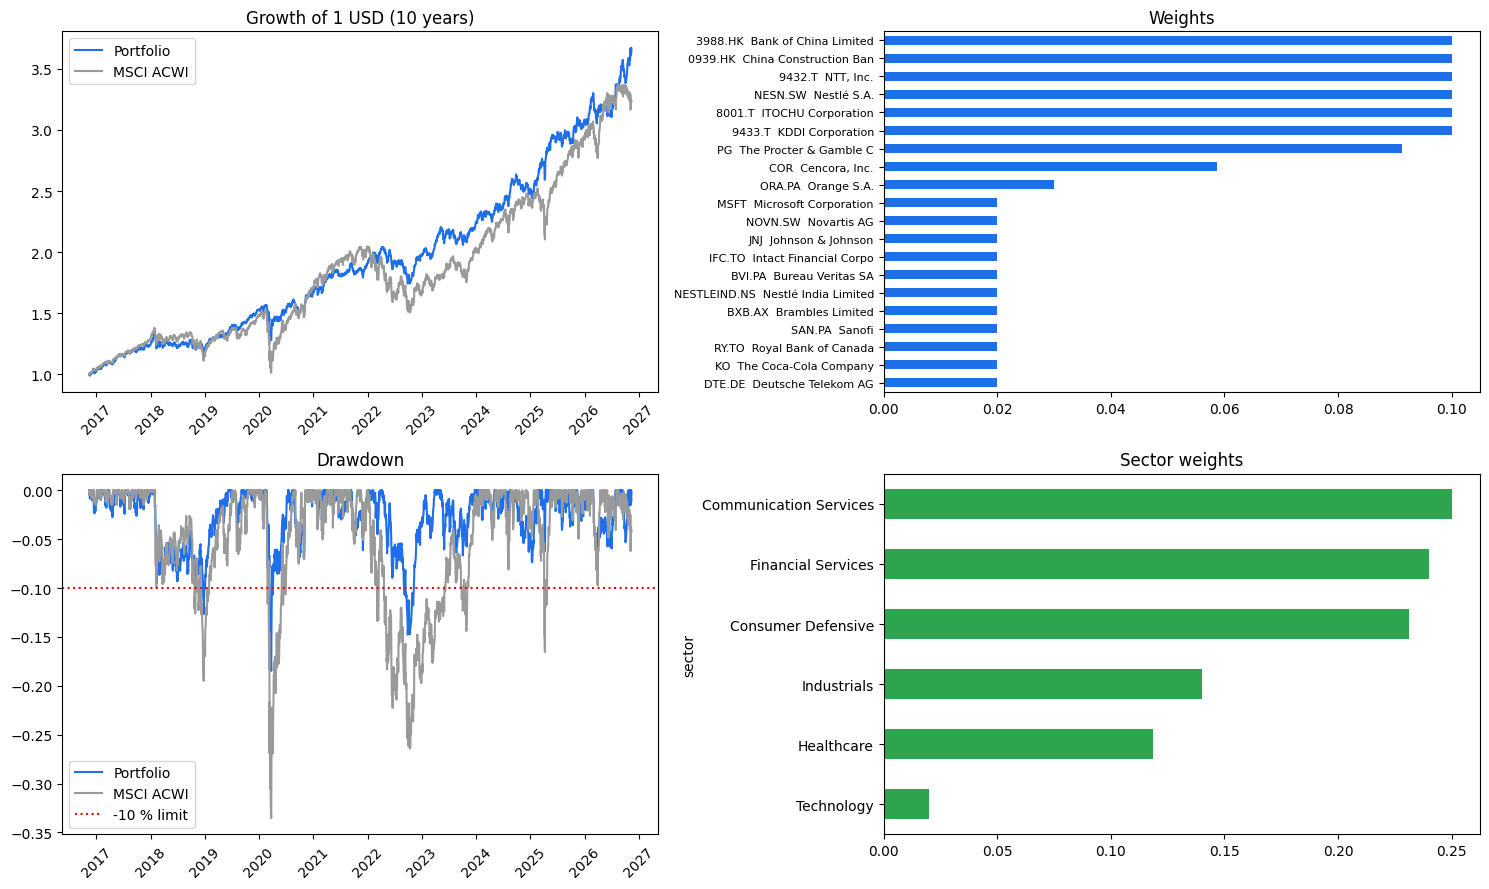

Saved final_20_portfolio.csv and selection_funnel.csv (Files panel)

FINAL 20:
0939.HK 10.0%, 3988.HK 10.0%, 9432.T 10.0%, 8001.T 10.0%, NESN.SW 10.0%, 9433.T 10.0%, PG 9.1%, COR 5.9%, ORA.PA 3.0%, MSFT 2.0%, NOVN.SW 2.0%, JNJ 2.0%, IFC.TO 2.0%, BVI.PA 2.0%, NESTLEIND.NS 2.0%, BXB.AX 2.0%, SAN.PA 2.0%, KO 2.0%, RY.TO 2.0%, DTE.DE 2.0%


In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
pr = R_fin.fillna(0) @ w; ar = acwi_base.loc[FINAL_START:].pct_change().iloc[1:]
for r, lab, col in [(pr, "Portfolio", "#1f6feb"), (ar, "MSCI ACWI", "#9a9a9a")]:
    cum = (1 + r).cumprod(); ax[0,0].plot(cum, label=lab, color=col); ax[1,0].plot(cum / cum.cummax() - 1, color=col, label=lab)
ax[1,0].axhline(-MAX_DRAWDOWN, color="red", ls=":", label="-10 % limit")
ax[0,0].set_title(f"Growth of 1 {BASE_CCY} ({LOOKBACK_YEARS} years)")
for a in (ax[0,0], ax[1,0]): a.tick_params(axis="x", labelrotation=45); ax[1,0].set_title("Drawdown"); ax[0,0].legend(); ax[1,0].legend()
final.weight.sort_values().plot.barh(ax=ax[0,1], color="#1f6feb"); ax[0,1].set_title("Weights")
ax[0,1].set_yticklabels([f"{t}  {final.at[t,'name'][:22]}" for t in final.weight.sort_values().index], fontsize=8)
final.groupby("sector").weight.sum().sort_values().plot.barh(ax=ax[1,1], color="#2da44e"); ax[1,1].set_title("Sector weights")
plt.tight_layout(); plt.show()

final.to_csv("final_20_portfolio.csv")
pd.Series(funnel).to_csv("selection_funnel.csv")
print("Saved final_20_portfolio.csv and selection_funnel.csv (Files panel)")
print("\nFINAL 20:"); print(", ".join(f"{t} {final.at[t,'weight']:.1%}" for t in final.index))

## Methodology notes
- **Beta**: 10 years of weekly returns. A stock passes only if its beta vs its **local index**, its beta vs **MSCI ACWI** (in USD) and Yahoo's beta are all ≤ 1.2. The final check recomputes beta with a different weekly anchor.
- **Stable revenue**: at least 3 fiscal years of revenue, no annual decline of more than 5 %, growth standard deviation ≤ 10 pts. It also carries 25 % of the ranking score.
- **Max drawdown**: a hard optimizer constraint at 8 %. It is validated three ways in-sample (rebalanced, buy & hold, monthly data) and once out-of-sample by re-running the whole pipeline as of 12 months ago.
- **Robustness**: liquidity ≥ $1M/day, bad-data filters, return shrinkage, 2–10 % per stock, ≤ 25 % per sector, ≤ 4 stocks per sector, ≤ 6 per country, one listing per company.
- **Limits**: past drawdowns don't guarantee future ones; revenue data comes from current statements, so the validation has slight look-ahead on that one screen; transaction costs are ignored.